### Pregunta 1


Para aproximar la primera derivada se utilizan diferencias finitas de primer, segundo y tercer orden. Estas expresiones se obtienen mediante expansiones de Taylor alrededor del punto de evaluación, considerando un paso constante $h=\Delta x$.

**Primer orden**

Expandiendo la función en $x+h$:

$$
f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+O(h^3)
$$

Despejando la primera derivada y despreciando los términos de orden superior:

$$
f'(x)\approx\frac{f(x+h)-f(x)}{h}
$$

Esta aproximación tiene un error de truncamiento $O(h)$.

**Segundo orden**

Se consideran las expansiones de Taylor en ambos sentidos:

$$
f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+\frac{h^3}{6}f'''(x)+\frac{h^4}{24}f^{(4)}(x)+O(h^5)
$$

$$
f(x-h)=f(x)-hf'(x)+\frac{h^2}{2}f''(x)-\frac{h^3}{6}f'''(x)+\frac{h^4}{24}f^{(4)}(x)+O(h^5)
$$

Al restar ambas expresiones, los términos pares se cancelan:

$$
f(x+h)-f(x-h)=2hf'(x)+\frac{h^3}{3}f'''(x)+O(h^5)
$$

Dividiendo por $2h$ y despreciando los términos de error:

$$
f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}
$$

El error de truncamiento es $O(h^2)$.

**Tercer orden**

Para obtener una aproximación de tercer orden se consideran cuatro puntos. Utilizando la expansión de Taylor con incrementos $kh$, para $k=1,2,3$:

$$
f(x+kh)=f(x)+khf'(x)+\frac{k^2h^2}{2}f''(x)+\frac{k^3h^3}{6}f'''(x)+O(h^4)
$$

Se combinan estas expansiones para cancelar los términos correspondientes a $f(x)$, $f''(x)$ y $f'''(x)$, conservando el término de la primera derivada.

La combinación resultante es:

$$
-11f(x)+18f(x+h)-9f(x+2h)+2f(x+3h)=6hf'(x)+O(h^4)
$$

Dividiendo por $6h$:

$$
f'(x)\approx\frac{-11f(x)+18f(x+h)-9f(x+2h)+2f(x+3h)}{6h}
$$

Esta aproximación tiene un error de truncamiento $O(h^3)$.

Finalmente, se evalúan las tres aproximaciones en $x=0.5$ con $h=0.25$, y se comparan con la derivada analítica mediante el error relativo.


In [6]:
def f(x):
    return -0.1*x**4 - 0.15*x**3 - 0.5*x**2 - 0.25*x + 1.2

def df(x):
    return -0.4*x**3 - 0.45*x**2 - x - 0.25

def df_primer_orden(x, h):
    return (f(x + h) - f(x)) / h

def df_segundo_orden(x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def df_tercer_orden(x, h):
    return (-11*f(x) + 18*f(x + h) - 9*f(x + 2*h) + 2*f(x + 3*h)) / (6*h)

x = 0.5
h = 0.25

print("Valor de la función en x =", x, "es:", f(x))
print("Valor de la derivada exacta en x =", x, "es:", df(x))
print("Valor de la derivada aproximada de primer orden en x =", x, "es:", df_primer_orden(x, h))
print("Valor de la derivada aproximada de segundo orden en x =", x, "es:", df_segundo_orden(x, h))
print("Valor de la derivada aproximada de tercer orden en x =", x, "es:", df_tercer_orden(x, h))
print("Error de la derivada aproximada de primer orden en x =", x, "es:", abs(df(x) - df_primer_orden(x, h))/abs(df(x))*100, "%")
print("Error de la derivada aproximada de segundo orden en x =", x, "es:", abs(df(x) - df_segundo_orden(x, h))/abs(df(x))*100, "%")
print("Error de la derivada aproximada de tercer orden en x =", x, "es:", abs(df(x) - df_tercer_orden(x, h))/abs(df(x))*100, "%")


Valor de la función en x = 0.5 es: 0.9249999999999999
Valor de la derivada exacta en x = 0.5 es: -0.9125
Valor de la derivada aproximada de primer orden en x = 0.5 es: -1.1546875
Valor de la derivada aproximada de segundo orden en x = 0.5 es: -0.9343750000000002
Valor de la derivada aproximada de tercer orden en x = 0.5 es: -0.9218749999999996
Error de la derivada aproximada de primer orden en x = 0.5 es: 26.541095890410972 %
Error de la derivada aproximada de segundo orden en x = 0.5 es: 2.3972602739726248 %
Error de la derivada aproximada de tercer orden en x = 0.5 es: 1.0273972602739263 %



### Análisis de resultados

La aproximación de primer orden presenta el mayor error relativo (26.54%). Al utilizar el esquema centrado de segundo orden, el error disminuye a 2.40%, mientras que con el esquema de tercer orden se reduce a 1.03%.

Para el paso utilizado, se observa que las aproximaciones de mayor orden entregan resultados más cercanos al valor analítico de $f'(0.5)=-0.9125$. Esto se debe a que las fórmulas de mayor orden eliminan más términos del error de truncamiento.


### Preunta 2


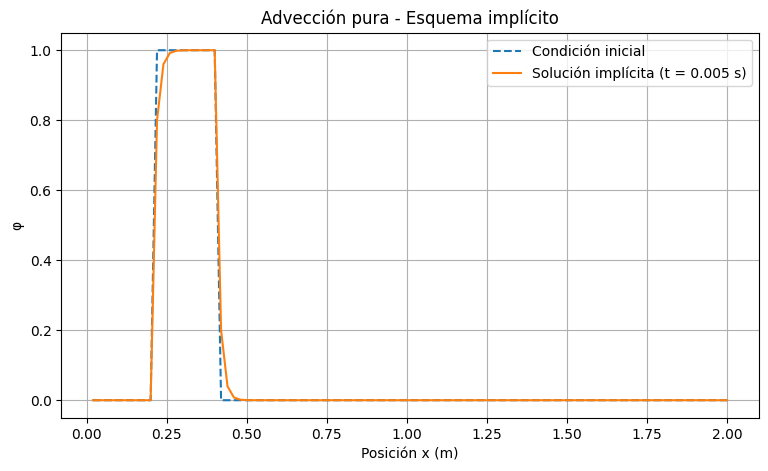

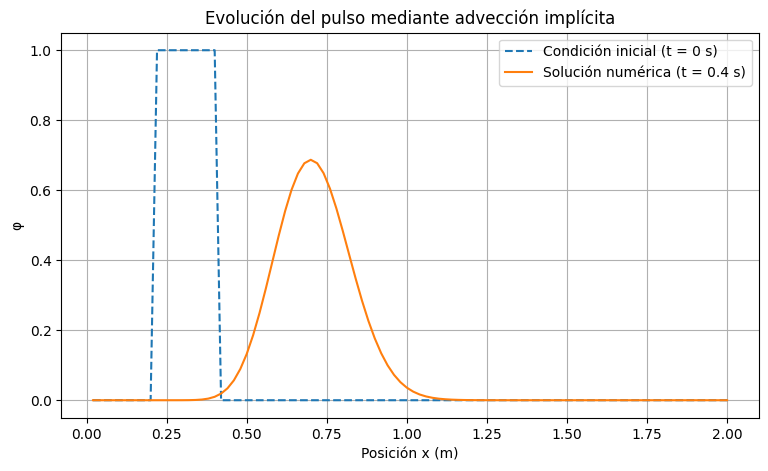

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def solucion_implicita(N, dx, dt, c, phi_actual, b):
    C = c * dt/dx
    A = np.zeros((N,N))
    for i in range(N):
        if i == 0:
            A[i][i] = 1 + C
        else:
            A[i][i] = 1 + C
            A[i][i-1] = -C
    return np.linalg.solve(A, phi_actual + b)


def simular_adveccion(N, dt, c, L, tf):
    dx = L / N
    x = np.linspace(dx, L, N)

    phi_inicial = np.zeros(N)
    phi_inicial[(x >= 0.2) & (x <= 0.4)] = 1.0

    phi_actual = phi_inicial.copy()
    b = np.zeros(N)

    Nt = int(round(tf / dt))

    for n in range(Nt):
        phi_actual = solucion_implicita(N, dx, dt, c, phi_actual, b)

    return x, phi_inicial, phi_actual


N = 100
L = 2.0
dx = L / N

dt = 0.005
c = 1.0
tf = 0.4

x = np.linspace(dx, L, N)

phi_inicial = np.zeros(N)
phi_inicial[(x >= 0.2) & (x <= 0.4)] = 1.0

phi_siguiente = solucion_implicita(N, dx, dt, c, phi_inicial, np.zeros(N))

x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)


plt.figure(figsize=(9, 5))

plt.plot(x, phi_inicial, label="Condición inicial", linestyle="--")
plt.plot(x, phi_siguiente, label="Solución implícita (t = 0.005 s)")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Advección pura - Esquema implícito")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(9, 5))

plt.plot(x, phi_inicial, "--", label="Condición inicial (t = 0 s)")
plt.plot(x, phi_final, label="Solución numérica (t = 0.4 s)")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Evolución del pulso mediante advección implícita")
plt.legend()
plt.grid(True)

plt.show()


### Cambio de $\Delta x$

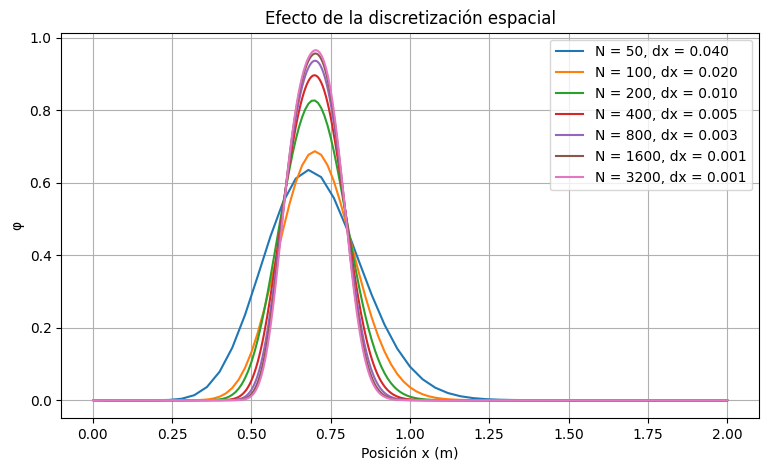

In [15]:

plt.figure(figsize=(9, 5))

for N in [50, 100, 200, 400, 800, 1600, 3200]:
    x, phi_inicial, phi_final = simular_adveccion(N, 0.005, 1.0, 2.0, 0.4)

    plt.plot(x, phi_final, label=f"N = {N}, dx = {2/N:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto de la discretización espacial")
plt.legend()
plt.grid(True)
plt.show()


### Cambio de $\Delta t$

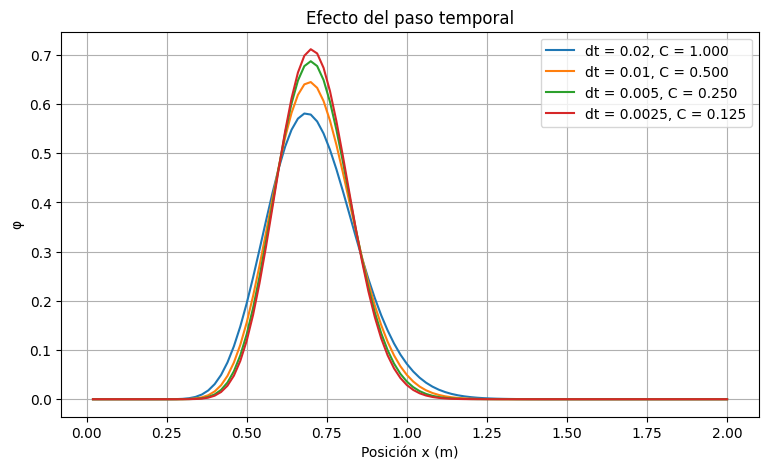

In [16]:

plt.figure(figsize=(9, 5))

N = 100
L = 2.0
c = 1.0
tf = 0.4

for dt in [0.02, 0.01, 0.005, 0.0025]:
    x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)

    C = c * dt / (L / N)

    plt.plot(x, phi_final, label=f"dt = {dt}, C = {C:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto del paso temporal")
plt.legend()
plt.grid(True)
plt.show()


### Cambio de c

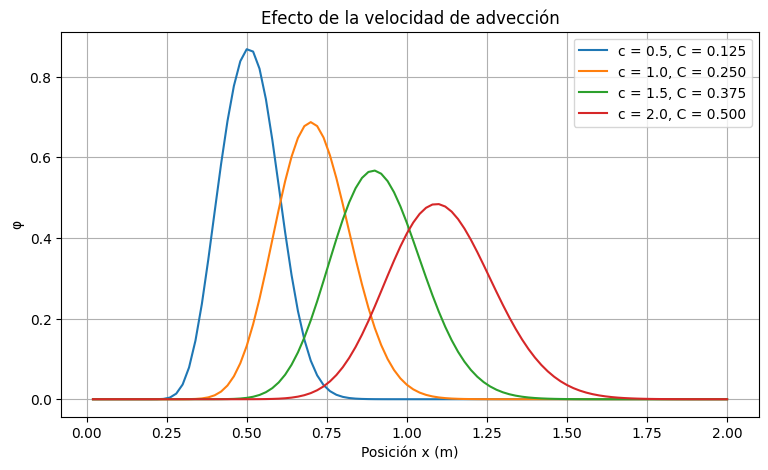

In [17]:

plt.figure(figsize=(9, 5))

N = 100
L = 2.0
dt = 0.005
tf = 0.4

for c in [0.5, 1.0, 1.5, 2.0]:
    x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)

    C = c * dt / (L / N)

    plt.plot(x, phi_final, label=f"c = {c}, C = {C:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto de la velocidad de advección")
plt.legend()
plt.grid(True)
plt.show()
